# Lab 2: Regularized Least Square
In this lab, we focus on RLS to address linear regression problems. We will:
1. Implement RLS to solve linear regression problems,
2. Observe performance of RLS changing the noise in the data and the regularization parameter,
3. Implement K-Fold Cross-Validation algorithm for RLS.

In [ ]:
# Import external libraries
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg

## Data generation
To generate linear regression data, we use the `linearRegrFunction` introduced in Lab 0.

In [ ]:
def linearRegrFunction(n, D, low_D, high_D, W, sigma_noise): #W array con i coefficenti della funzione lineare
    X = np.zeros((n,D))
    for i in range(0, D):
        X[:,i] = np.random.uniform(low_D[i], high_D[i], size=n)

    gauss_noise = np.random.normal(0, sigma_noise, size=(n,1))

    Y = np.dot(X, W) + gauss_noise

    return X, Y

### Example: Noiseless dataset


Text(0, 0.5, 'y')

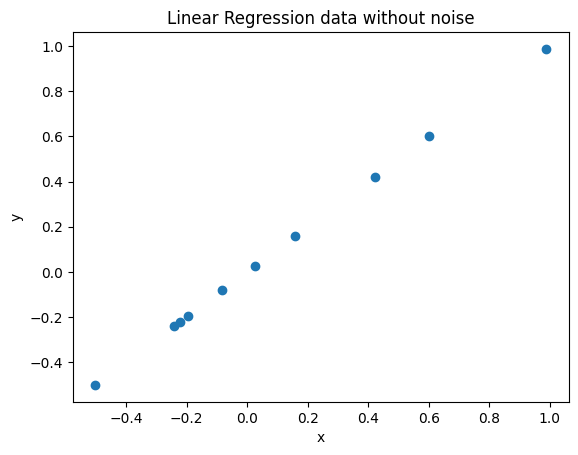

In [ ]:
n = 10
D = 1
low_D, high_D = [-1], [1]
w = 1
noise_std = 0.0

# Data generation
X, Y = linearRegrFunction(n, D, low_D, high_D, w, noise_std)

# Plot data
plt.scatter(X, Y)
plt.title("Linear Regression data without noise")
plt.xlabel("x")
plt.ylabel("y")

## Task 1: RLS regressor
We want to implement the `regularizedLSTrain` function which train RLS regression.

The signature of `regularizedLSTrain` is the following:

`w = regularizedLSTrain(Xtr, Ytr, lam)`

where:
- **Xtr** are the training inputs
- **Ytr** are the training outputs
- **lam** is the regularization parameter $\lambda$

To implement this function, you will need to use the following functions from numpy:

- [`np.linalg.cholesky`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.cholesky.html)
- [`scipy.linalg.solve_triangular`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.solve_triangular.html)

Consider

**$(X_{tr}^\intercal X_{tr} + \lambda n I)w = X_{tr}^\intercal Y_{tr}$**

Let $A = X_{tr}^\intercal X_{tr} + \lambda n I$ and $b = X_{tr}^\intercal Y_{tr}$, we can find $w$ with the following steps:
1. First build the left-hand side matrix `A`, and the right-hand side matrix `b`.
2. Compute the Cholesky decomposition of `A` (note that the numpy function will provide a lower-triangular matrix)
3. You will have to solve two triangular systems, one using the Cholesky decomposition, and the other using its transpose.

In [ ]:
def regularizedLSTrain(Xtr, Ytr, lam): #Aw = b
    # Insert your code here
    A = Xtr.T @ Xtr + lam*Xtr.shape[0]*np.eye(Xtr.shape[1])
    b = Xtr.T @ Ytr

    # Compute the Cholesky decomposition of A , cholensky non conviene computazionalmente , operazione costosa
    L = np.linalg.cholesky(A) #L matrice triangolare inferiore tc L @ L.t = A ,  A deve essere simmetrica e definita positiva e lo è

    y = scipy.linalg.solve_triangular(L, b, lower=True)
    w = scipy.linalg.solve_triangular(L.T, y, lower=False)
    return w

#scelta di lambda difficile , si usa Cross Validation, una volta trovato il lambda ideale , rialleno il dataset e trovo wstar con lambda ideale

We need also to implement a function `regularizedLSTest` which given a test set `Xte` and the `w` obtained using `regularizedLSTrain`, it returns `Ypred` containing the predictions

In [ ]:
def regularizedLSTest(w, Xte):
    # Insert your code here
    return Xte @ w #Ypred = <wlam , xnew>

To evaluate the performance of RLS regressor, we need a function to estimate the error.

Given two vectors `Ytrue` (real outputs) and `Ypred` (predicted outputs), we can measure the error obtained when predicting `Ypred` instead of `Ytrue` with the MSE (Mean Square Error)

In [ ]:
def calcError(Ypred, Ytrue):
    return np.mean((Ypred-Ytrue)**2)

Now we can build an easy example to observe how our model works:
- Generate a training set with **ntrain** points and a test set with **ntest** points
- Train RLS with `regularizedLSTrain` function and test it with `regularizedLSTest` on test set
- Compute the training and test error

In [ ]:
ntrain = 100
ntest = 50
D = 1
low_D = [-1]
high_D = [5]
w = np.random.randn(D, 1)
noise_std = 0.1

lam = 1e-3

# Generate a training set with ntrain points and a test set with ntest
Xtr, Ytr = linearRegrFunction(ntrain,D,low_D,high_D,w,noise_std)
Xte, Yte = linearRegrFunction(ntest,D,low_D,high_D,w,noise_std)

# Train RLS
w = regularizedLSTrain(Xtr,Ytr,lam)

# Compute predictions on training and test set
Ytr_pred = regularizedLSTest(w,Xtr)
Yte_pred = regularizedLSTest(w,Xte)

train_err = calcError(Ytr_pred,Ytr)
test_err = calcError(Yte_pred,Yte)

print(f'Training error: {train_err}\t Test error: {test_err}')

Training error: 0.010115441069926148	 Test error: 0.007677788827670571


## Task 2: Changing $\lambda$
Now we can play with our model changing the noise level in the data and changing the $\lambda$ parameter.

Let's start by changing $\lambda$ and fixing the other parameters.

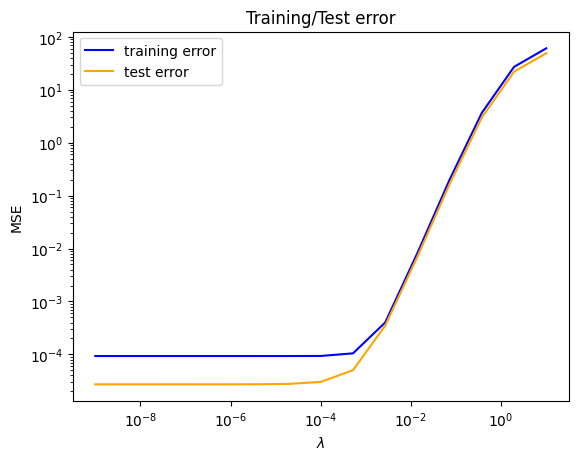

In [ ]:
ntrain = 500
ntest = 10
D = 2
low_D = [-2] * D
high_D = [2] * D
w = [[7], [3]]
noise_std = 0.01 #0.5

# Data generation
Xtr, Ytr = linearRegrFunction(ntrain, D, low_D, high_D, w, noise_std)
Xte, Yte = linearRegrFunction(ntest, D, low_D, high_D, w, noise_std)

lam_list = np.logspace(start=-9, stop=1, num=15)
tr_err = []
te_err = []

for lam in lam_list:
    # Train RLS
    w = regularizedLSTrain(Xtr, Ytr, lam)
    # Compute predictions on training and test set
    Ytr_pred = regularizedLSTest(w,Xtr)
    Yte_pred = regularizedLSTest(w,Xte)

    # Compute training and test error and store them on tr_err and te_err
    errTR = calcError(Ytr_pred,Ytr)
    errTE = calcError(Yte_pred,Yte)
    tr_err.append(errTR)
    te_err.append(errTE)

# Plot training and test error in log-log
plt.loglog(lam_list, tr_err, '-', c="blue", label="training error") #entrambi gli assi in scala logaritmica
plt.loglog(lam_list, te_err, '-', c="orange", label="test error")
plt.xlabel("$\lambda$")
plt.ylabel("MSE")
plt.title("Training/Test error")
plt.legend()

*What happens when $\lambda$ increases?*

---



## Task 3: K-Fold Cross Validation for RLS
Now, we want to implement the K-Fold Cross Validation for RLS.

We want to implement the `KFoldCVRLS` function which, given a training set **Xtr** and **Ytr**, a number of folds **KF** and a set of values for $\lambda$ (**regpar_list**), returns:

*   **bestlam**: the $\lambda$ which minimizes the mean validation error,
*   **val_mean**: the mean validation error,
*   **val_var**: the validation error variance,
*   **tr_mean**: the mean training error,
*   **tr_var**: the training error variance.

`bestlam, val_mean, val_var, tr_mean, tr_var = KFoldCVRLS(Xtr, Ytr, KF, regpar_list)`

**Hint:** this function is very similar to K-Fold Cross-Validation algorithm for KNN (Lab 1)

In [ ]:
def KFoldCVRLS(Xtr, Ytr, KF, regpar_list):
    if KF <= 1:
        raise Exception("Please supply a number of fold > 1")

    # Ensures that regpar_list is a numpy array
    regpar_list = np.array(regpar_list)
    num_regpar = regpar_list.size

    n_tot = Xtr.shape[0]
    n_val = int(n_tot / KF)

    # We want to compute 1 error for each lambda and each fold
    tr_errors = np.zeros((num_regpar, KF))
    val_errors = np.zeros((num_regpar, KF))

    for idx, regpar in enumerate(regpar_list):
        # split_idx: a list of arrays, each containing the validation indices for 1 fold
        rand_idx = np.arange(n_tot) # create array of indexes (here ordered)
        np.random.shuffle(rand_idx) # shuffle it!

        # split the array of indexes in KF smaller arrays
        split_idx = np.array_split(rand_idx, KF)

        for fold in range(KF):
            # Set the indices in boolean mask for all validation samples to `True`
            val_mask = np.zeros(n_tot, dtype=bool)
            val_mask[split_idx[fold]] = True

            # Use the boolean mask to split X, Y in training and validation part

            X =  Xtr[~val_mask] # training input
            Y =  Ytr[~val_mask] # training output
            X_val = Xtr[val_mask] # validation input
            Y_val = Ytr[val_mask] # validation output

            # Train a RLS model for a single fold, and the given value of `regpar`
            currW = regularizedLSTrain(X, Y, regpar)

            # Compute the training error of the RLS regression for the given value of regpar
            YpredTR = regularizedLSTest(currW, X)
            tr_errors[idx, fold] = calcError(YpredTR, Y)

            # Compute the validation error of the RLS regression for the given value of regpar
            YpredVAL = regularizedLSTest(currW, X_val)
            val_errors[idx, fold] = calcError(YpredVAL, Y_val)

    # Calculate error statistics along the folds
    tr_mean = np.mean(tr_errors, axis=1)
    tr_var = np.var(tr_errors, axis=1)
    val_mean = np.mean(val_errors, axis=1)
    val_var = np.var(val_errors, axis=1)

    bestlam_idx = np.argmin(val_mean)
    bestlam = regpar_list[bestlam_idx]

    return bestlam, val_mean, val_var, tr_mean, tr_var

Use `KFoldCVRLS` to find the best regularization parameter

Best lambda found: 0.0011497569953977356


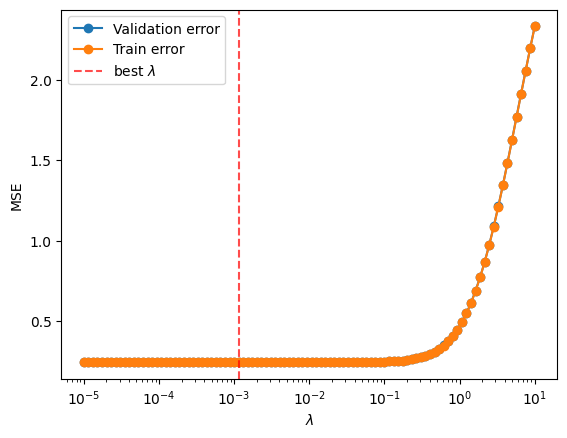

In [ ]:
n = 1000
D = 1
sigma_noise = 0.5
truew = np.random.randn(D, 1)
reg_pars = np.logspace(-5, 1, 100)
KF = 5

low_D = [-3] * D
high_D = [3] * D

# Generate training set
Xtr, Ytr =  linearRegrFunction(n ,D, low_D, high_D, truew , sigma_noise)

# Compute best lambda
bestlam, Vm, Vs, Tm, Ts = KFoldCVRLS(Xtr, Ytr, KF, reg_pars)
print(f'Best lambda found: {bestlam}')

# Plot training and validation error
plt.plot(reg_pars, Vm, '-o', label="Validation error")
plt.plot(reg_pars, Tm, '-o', label="Train error")
plt.axvline(bestlam, linestyle="--", c="red", alpha=0.7, label="best $\lambda$")
plt.xscale("log")
plt.xlabel("$\lambda$")
plt.ylabel("MSE")
plt.legend()

Plot the regression curve using the best $\lambda$ (found with `KFoldCVRLS`) and using the worsk $\lambda$

Best lambda found: 0.0011497569953977356


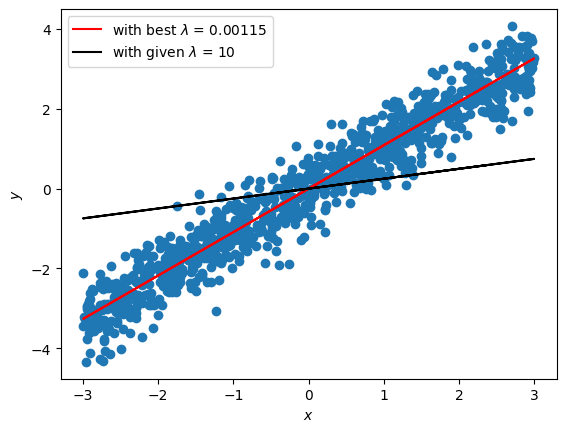

In [ ]:
given_lam = 10
print(f'Best lambda found: {bestlam}')
w_best = regularizedLSTrain(Xtr, Ytr, bestlam)
Ypred_best = regularizedLSTest(w_best, Xtr)

w_given = regularizedLSTrain(Xtr, Ytr, given_lam)
Ypred_smthg = regularizedLSTest(w_given, Xtr)

plt.scatter(Xtr, Ytr)
plt.plot(Xtr, Ypred_best, '-',c="red", label=f"with best $\lambda$ = {bestlam:.5f}")
plt.plot(Xtr, Ypred_smthg, '-',c="black", label=f"with given $\lambda$ = {given_lam}")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()

Use the best $\lambda$ found to train the model on the full training set and compute the test error on the following test set.   

In [ ]:
Xte, Yte = linearRegrFunction(200, D, low_D, high_D, truew, sigma_noise)

print(f'Best lambda found: {bestlam}')

w_best = regularizedLSTrain(Xtr, Ytr, bestlam)
Ypred_best = regularizedLSTest(w_best, Xte)
test_err = calcError(Ypred_best, Yte)

print(f"Test error: {test_err}")

Best lambda found: 6.135907273413175e-05
Test error: 0.26687349929894155


### Repeat the procedure on a different dataset, with D=2

---

Create new training **and** test datasets, sampled in a non-symmetric range (for example you can set the `low_D` and `high_D` parameters of the `linearRegrFunction` function to 2 and 5).

Then repeat the K-fold CV procedure, and check whether the best regularization parameter changes!

Best lambda found: 7.054802310718646e-05


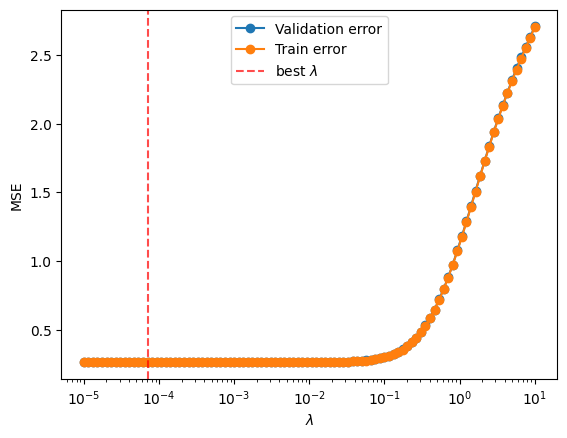

In [ ]:
# Insert your code here
n=1000
D=2
low_D=[2]*D
high_D=[5]*D

sigma_noise = 0.5
truew = np.random.randn(D, 1)
KF = 5

# Generate training set
Xtr, Ytr =  linearRegrFunction(n ,D, low_D, high_D, truew , sigma_noise)

# Compute best lambda
bestlam, Vm, Vs, Tm, Ts = KFoldCVRLS(Xtr, Ytr, KF, reg_pars)
print(f'Best lambda found: {bestlam}')

# Plot training and validation error

plt.plot(reg_pars, Vm, '-o', label="Validation error")
plt.plot(reg_pars, Tm, '-o', label="Train error")
plt.axvline(bestlam, linestyle="--", c="red", alpha=0.7, label="best $\lambda$")
plt.xscale("log")
plt.xlabel("$\lambda$")
plt.ylabel("MSE")
plt.legend()

C:\Users\edoar\AppData\Local\Temp\ipykernel_18940\3833816276.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_macro_valid["label"] = (


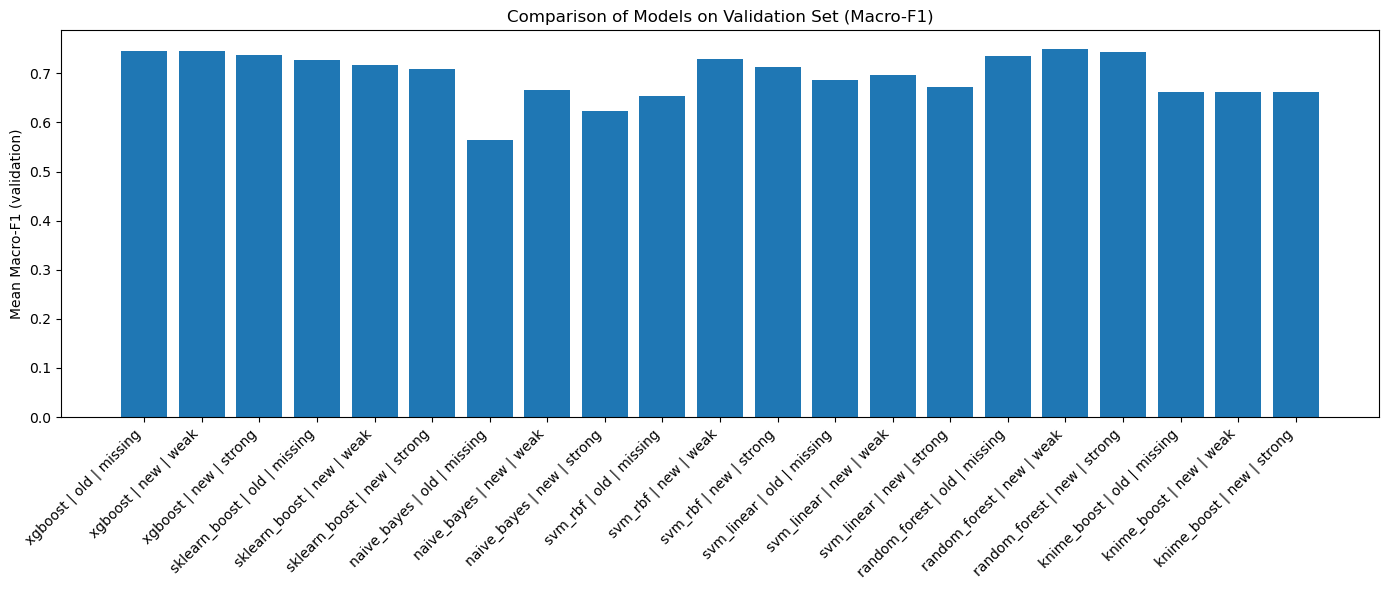

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# 1. Load dataset
# =========================
df = pd.read_csv(r"C:\Users\edoar\OneDrive\Desktop\UniMib_DataScience\MachineLearning\Progetto\metrics.csv")

# =========================
# 2. Filter data
#    - validation split
#    - Mean macro-f1 metric
# =========================
df_macro_valid = df[
    (df["measure"] == "Mean(macro-f1)") &
    (df["split"] == "valid")
]

# =========================
# 3. Create labels for x-axis
# =========================
df_macro_valid["label"] = (
    df_macro_valid["algo"] + " | " +
    df_macro_valid["features"] + " | " +
    df_macro_valid["filter"]
)

# =========================
# 4. Plot
# =========================
plt.figure(figsize=(14, 6))
plt.bar(df_macro_valid["label"], df_macro_valid["metric_value"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Mean Macro-F1 (validation)")
plt.title("Comparison of Models on Validation Set (Macro-F1)")
plt.tight_layout()
plt.show()


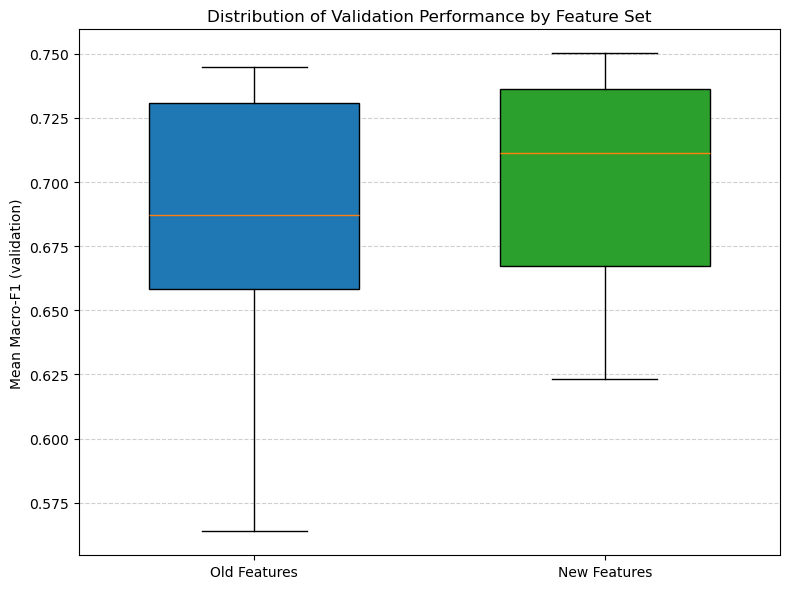

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# 1. Load dataset
# =========================
df = pd.read_csv(r"C:\Users\edoar\OneDrive\Desktop\UniMib_DataScience\MachineLearning\Progetto\metrics.csv")

# =========================
# 2. Filter relevant data
# =========================
df_macro_valid = df[
    (df["measure"] == "Mean(macro-f1)") &
    (df["split"] == "valid")
]

# =========================
# 3. Separate feature groups
# =========================
old_features = df_macro_valid[df_macro_valid["features"] == "old"]["metric_value"]
new_features = df_macro_valid[df_macro_valid["features"] == "new"]["metric_value"]

# =========================
# 4. Boxplot
# =========================
plt.figure(figsize=(8, 6))

box = plt.boxplot(
    [old_features, new_features],
    labels=["Old Features", "New Features"],
    patch_artist=True,
    widths=0.6
)

# Colors
colors = ["#1f77b4", "#2ca02c"]  # blue / green
for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)

# Styling
plt.ylabel("Mean Macro-F1 (validation)")
plt.title("Distribution of Validation Performance by Feature Set")
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


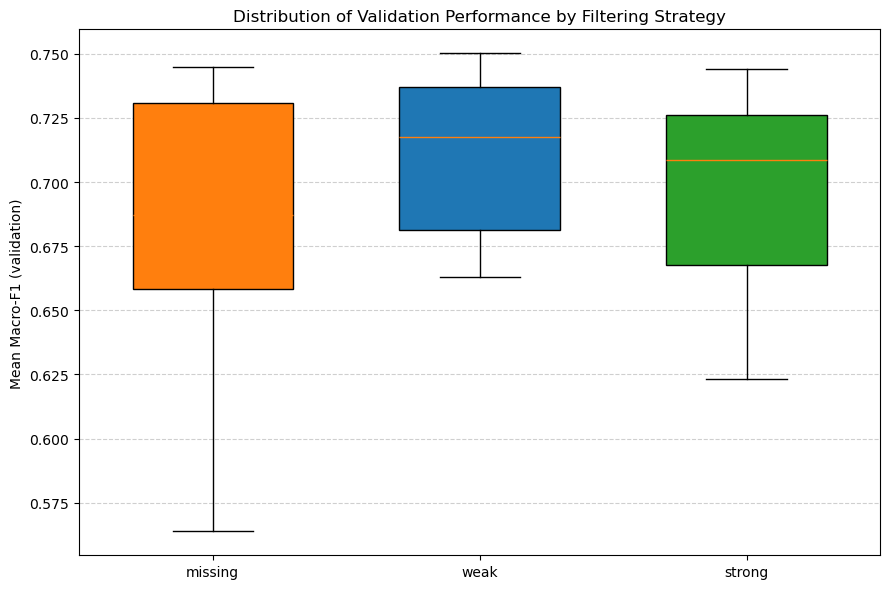

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# 1. Load dataset
# =========================
df = pd.read_csv(r"C:\Users\edoar\OneDrive\Desktop\UniMib_DataScience\MachineLearning\Progetto\metrics.csv")

# =========================
# 2. Filter relevant data
# =========================
df_macro_valid = df[
    (df["measure"] == "Mean(macro-f1)") &
    (df["split"] == "valid")
]

# =========================
# 3. Group by filtering strategy
# =========================
filters = df_macro_valid["filter"].unique()
data = [
    df_macro_valid[df_macro_valid["filter"] == f]["metric_value"]
    for f in filters
]

# =========================
# 4. Boxplot
# =========================
plt.figure(figsize=(9, 6))

box = plt.boxplot(
    data,
    labels=filters,
    patch_artist=True,
    widths=0.6
)

# Colors (one per filter)
colors = ["#ff7f0e", "#1f77b4", "#2ca02c"][:len(filters)]
for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)

# Styling
plt.ylabel("Mean Macro-F1 (validation)")
plt.title("Distribution of Validation Performance by Filtering Strategy")
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


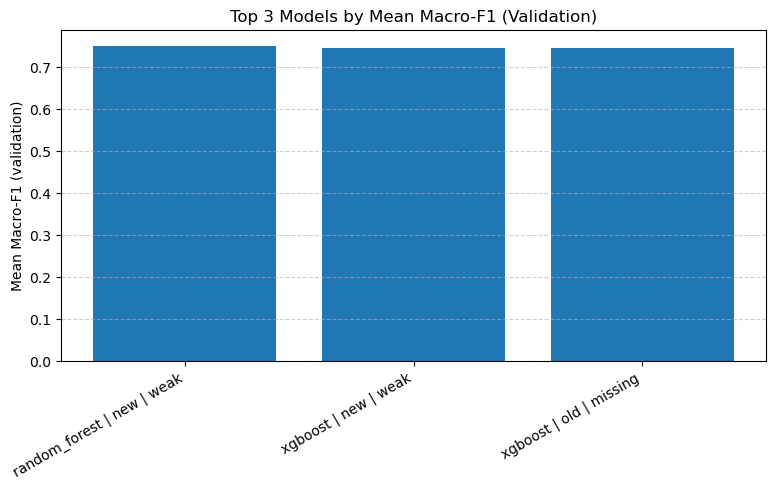

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv(r"C:\Users\edoar\OneDrive\Desktop\UniMib_DataScience\MachineLearning\Progetto\metrics.csv")

# Filter Macro-F1 on validation
df_macro_valid = df[
    (df["measure"] == "Mean(macro-f1)") &
    (df["split"] == "valid")
]

# Select top 3 models
top3_macro = df_macro_valid.sort_values(
    by="metric_value", ascending=False
).head(3)

labels_top3 = (
    top3_macro["algo"] + " | " +
    top3_macro["features"] + " | " +
    top3_macro["filter"]
)

plt.figure(figsize=(8, 5))
plt.bar(labels_top3, top3_macro["metric_value"], color="#1f77b4")
plt.ylabel("Mean Macro-F1 (validation)")
plt.title("Top 3 Models by Mean Macro-F1 (Validation)")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


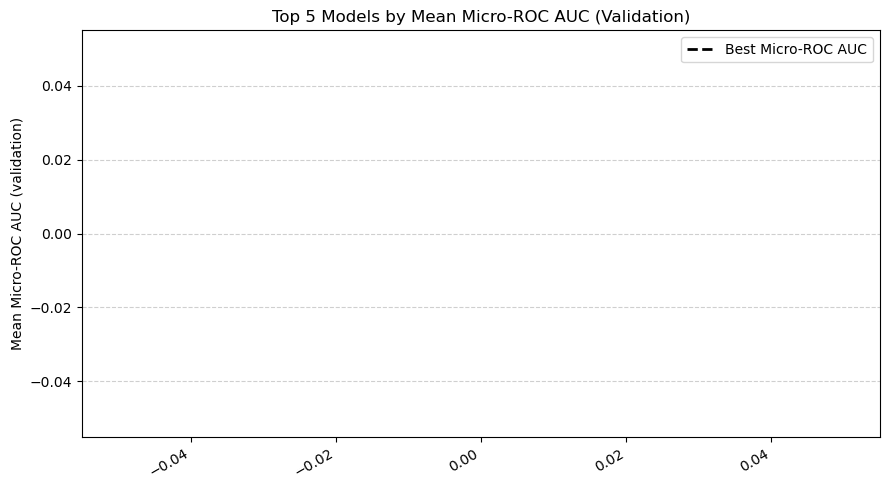

In [ ]:
# Filter Micro-ROC AUC on validation
df_micro_valid = df[
    (df["measure"] == "Mean(micro-rocauc)") &
    (df["split"] == "valid")
]

# Select top 5 models
top5_micro = df_micro_valid.sort_values(
    by="metric_value", ascending=False
).head(5)

labels_top5 = (
    top5_micro["algo"] + " | " +
    top5_micro["features"] + " | " +
    top5_micro["filter"]
)

# Colors: top 3 highlighted
colors = ["#d62728", "#d62728", "#d62728", "#7f7f7f", "#7f7f7f"]

best_value = top5_micro["metric_value"].max()

plt.figure(figsize=(9, 5))
plt.bar(labels_top5, top5_micro["metric_value"], color=colors)

# Horizontal line at best value
plt.axhline(
    y=best_value,
    linestyle="--",
    linewidth=2,
    color="black",
    label="Best Micro-ROC AUC"
)

plt.ylabel("Mean Micro-ROC AUC (validation)")
plt.title("Top 5 Models by Mean Micro-ROC AUC (Validation)")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()
